# Actividad de Aprendizaje 1: Entendimiento y Exploración de Datos
**Caso de Negocio:** North Quay Gifts | **Dataset:** Online Retail II  
**Fase CRISP-DM:** Phase 2 — Data Understanding  
**Equipo de Trabajo:**
- Russel Emmanuel Ku Aguilar (2309131@upy.edu.mx)
- Damian Nicolas Sanchez Novelo (2109134@upy.edu.mx)
- Jonathan Abisai Velasco Martín (2309060@upy.edu.mx)
- Ángel Rivaldo Canché Chuc (2309030@upy.edu.mx)
- Bianca Alexandra Acosta Castellanos (2309001@upy.edu.mx)

**Profesor Titular:** Didier Omar Gamboa Angulo (didier.gamboa@upy.edu.mx)  
**Institución:** Universidad Politécnica de Yucatán (UPY) — Faculty of Data Engineering

---
### Propósito y Alcance Metodológico
El presente cuaderno implementa de manera rigurosa, reproducible y verificable todas las investigaciones de la Fase de Entendimiento de Datos (CRISP-DM Phase 2) sobre el repositorio transaccional `online_retail_II.csv`. 

Siguiendo estrictamente los lineamientos de la actividad:
- **No se eliminan, imputan ni modifican registros** en el dataset base.
- **No se calculan variables derivadas** (como `LineAmount`) ni agregaciones que sustituyan las observaciones atómicas.
- Las visualizaciones e inspecciones cuantifican líneas del archivo, distinguiendo meticulosamente transacciones (`Invoice`), clientes (`Customer ID`) y líneas de pedido.
- Todas las salidas respaldan y coinciden unívocamente con el reporte formal IEEE y la guía técnica de registro.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

# Configuraciones estéticas para gráficos académicos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica', 'Arial', 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Carpeta para figuras generadas
os.makedirs("figures", exist_ok=True)
print("Entorno analítico inicializado con éxito.")

Entorno analítico inicializado con éxito.


---
## 1. Reconocimiento de los Datos
Identificación de dimensiones, tipos de almacenamiento, cobertura cronológica real y semántica analítica de cada columna.

In [2]:
# Carga del conjunto de datos completo
data_path = "../Data/online_retail_II.csv" if os.path.exists("../Data/online_retail_II.csv") else "Data/online_retail_II.csv"
df = pd.read_csv(data_path, encoding='utf-8')

# Dimensiones originales
n_rows, n_cols = df.shape
print(f"Dimensiones del dataset: {n_rows:,} filas × {n_cols} columnas")
df.head(3)

Dimensiones del dataset: 1,067,371 filas × 8 columnas


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.9500,13085.0000,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.7500,13085.0000,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.7500,13085.0000,United Kingdom


In [3]:
# Conversión temporal para identificar cobertura real
df['InvoiceDateParsed'] = pd.to_datetime(df['InvoiceDate'])
min_datetime = df['InvoiceDateParsed'].min()
max_datetime = df['InvoiceDateParsed'].max()

# Cardinalidad de transacciones y clientes identificados
distinct_invoices = df['Invoice'].nunique()
distinct_identified_customers = df['Customer ID'].dropna().nunique()

recognition_summary = pd.DataFrame({
    'Indicador': [
        'Número de líneas y columnas',
        'Primera fecha con hora',
        'Última fecha con hora',
        'Facturas distintas (Invoice)',
        'Clientes identificados distintos (Customer ID)',
        'Unidad representada por una fila'
    ],
    'Resultado': [
        f"{n_rows:,} filas × {n_cols} columnas",
        str(min_datetime),
        str(max_datetime),
        f"{distinct_invoices:,}",
        f"{distinct_identified_customers:,}",
        "Línea de ítem/producto dentro de una factura comercial"
    ]
})
recognition_summary

,Indicador,Resultado
0,Número de líneas y columnas,"1,067,371 filas × 8 columnas"
1,Primera fecha con hora,2009-12-01 07:45:00
2,Última fecha con hora,2011-12-09 12:50:00
3,Facturas distintas (Invoice),"53,628"
4,Clientes identificados distintos (Customer ID),"5,942"
5,Unidad representada por una fila,Línea de ítem/producto dentro de una factura c...


In [4]:
# Clasificación funcional de variables
variable_taxonomy = pd.DataFrame([
    {"Columna": "Invoice", "Tipo en Pandas": str(df['Invoice'].dtype), "Tipo Analítico": "Nominal / Identificador", "Función y Significado": "Código alfanumérico único por orden. Prefijo 'C' indica transacción de cancelación."},
    {"Columna": "StockCode", "Tipo en Pandas": str(df['StockCode'].dtype), "Tipo Analítico": "Nominal / Alfanumérico", "Función y Significado": "Código de catálogo de producto o partida operativa (e.g. POST, D, M, B)."},
    {"Columna": "Description", "Tipo en Pandas": str(df['Description'].dtype), "Tipo Analítico": "Cualitativa Textual", "Función y Significado": "Nombre comercial del producto o glosa de notas internas y mermas."},
    {"Columna": "Quantity", "Tipo en Pandas": str(df['Quantity'].dtype), "Tipo Analítico": "Cuantitativa Discreta", "Función y Significado": "Unidades mercantiles facturadas. Valores negativos denotan anulaciones o mermas."},
    {"Columna": "InvoiceDate", "Tipo en Pandas": str(df['InvoiceDate'].dtype), "Tipo Analítico": "Temporal / Cronológica", "Función y Significado": "Marca de tiempo exacta (timestamp) de emisión de la orden."},
    {"Columna": "Price", "Tipo en Pandas": str(df['Price'].dtype), "Tipo Analítico": "Cuantitativa Continua", "Función y Significado": "Precio unitario de venta en Libras Esterlinas (GBP)."},
    {"Columna": "Customer ID", "Tipo en Pandas": str(df['Customer ID'].dtype), "Tipo Analítico": "Nominal / Clave Cliente", "Función y Significado": "Identificador único de comprador registrado. Los nulos representan compras sin tracking o ventas anónimas."},
    {"Columna": "Country", "Tipo en Pandas": str(df['Country'].dtype), "Tipo Analítico": "Cualitativa Nominal", "Función y Significado": "País geográfico asociado a la cuenta de facturación del cliente."}
])
variable_taxonomy

,Columna,Tipo en Pandas,Tipo Analítico,Función y Significado
0,Invoice,object,Nominal / Identificador,Código alfanumérico único por orden. Prefijo '...
1,StockCode,object,Nominal / Alfanumérico,Código de catálogo de producto o partida opera...
2,Description,object,Cualitativa Textual,Nombre comercial del producto o glosa de notas...
3,Quantity,int64,Cuantitativa Discreta,Unidades mercantiles facturadas. Valores negat...
4,InvoiceDate,object,Temporal / Cronológica,Marca de tiempo exacta (timestamp) de emisión ...
5,Price,float64,Cuantitativa Continua,Precio unitario de venta en Libras Esterlinas ...
6,Customer ID,float64,Nominal / Clave Cliente,Identificador único de comprador registrado. L...
7,Country,object,Cualitativa Nominal,País geográfico asociado a la cuenta de factur...


In [5]:
# Pregunta 1: Factura multi-ítem y discrepancia entre líneas y códigos únicos
# Seleccionamos Invoice '489517' que presenta múltiples productos y duplicidad interna
inv_target = "489517"
df_target_inv = df[df['Invoice'] == inv_target]
total_lines_inv = len(df_target_inv)
unique_codes_inv = df_target_inv['StockCode'].nunique()

print(f"Factura Analizada: {inv_target}")
print(f"Número total de líneas: {total_lines_inv}")
print(f"Número de StockCodes distintos: {unique_codes_inv}")
print(f"Diferencia (líneas duplicadas de mismo producto): {total_lines_inv - unique_codes_inv}")

# Mostramos los códigos repetidos dentro de la factura
code_counts = df_target_inv['StockCode'].value_counts()
print("\nStockCodes que aparecen más de una vez en esta misma factura:")
print(code_counts[code_counts > 1].head(5))

Factura Analizada: 489517
Número total de líneas: 38
Número de StockCodes distintos: 28
Diferencia (líneas duplicadas de mismo producto): 10

StockCodes que aparecen más de una vez en esta misma factura:
StockCode
21912    3
21913    2
22319    2
21821    2
21791    2
Name: count, dtype: int64


In [6]:
# Pregunta 3: Cobertura mensual en extremos del horizonte temporal
df['YearMonth'] = df['InvoiceDateParsed'].dt.to_period('M')
monthly_coverage = df.groupby('YearMonth').agg(
    Lineas=('Invoice', 'count'),
    Facturas_Unicas=('Invoice', 'nunique'),
    Primer_Timestamp=('InvoiceDateParsed', 'min'),
    Ultimo_Timestamp=('InvoiceDateParsed', 'max'),
    Dias_Activos=('InvoiceDateParsed', lambda x: x.dt.day.nunique())
)
print("Cobertura mensual en los meses inicial y terminal:")
monthly_coverage.iloc[[0, 1, -2, -1]]

Cobertura mensual en los meses inicial y terminal:


,Lineas,Facturas_Unicas,Primer_Timestamp,Ultimo_Timestamp,Dias_Activos
YearMonth,,,,,
2009-12,45228,2330,2009-12-01 07:45:00,2009-12-23 16:58:00,21
2010-01,31555,1633,2010-01-04 09:24:00,2010-01-31 16:02:00,24
2011-11,84711,3462,2011-11-01 08:16:00,2011-11-30 17:42:00,26
2011-12,25526,1015,2011-12-01 08:12:00,2011-12-09 12:50:00,8


---
## 2. Estadística Descriptiva
Medidas de tendencia central, dispersión, extremos y momentos de forma (asimetría y curtosis) para las variables numéricas métricas (`Quantity` y `Price`), excluyendo identificadores nominales.

In [7]:
# Métricas cuantitativas de Quantity y Price
desc_stats_table = pd.DataFrame({
    'Estadístico': [
        'Observaciones no nulas',
        'Media',
        'Mediana',
        'Desviación estándar',
        'Mínimo',
        'Primer cuartil (Q1 - 25%)',
        'Tercer cuartil (Q3 - 75%)',
        'Máximo',
        'Asimetría (Skewness)',
        'Curtosis (Fisher Excess Kurtosis)'
    ],
    'Quantity en unidades': [
        f"{df['Quantity'].count():,}",
        f"{df['Quantity'].mean():.4f}",
        f"{df['Quantity'].median():.4f}",
        f"{df['Quantity'].std():.4f}",
        f"{df['Quantity'].min():,}",
        f"{df['Quantity'].quantile(0.25):.4f}",
        f"{df['Quantity'].quantile(0.75):.4f}",
        f"{df['Quantity'].max():,}",
        f"{df['Quantity'].skew():.4f}",
        f"{df['Quantity'].kurt():.4f}"
    ],
    'Price en GBP por unidad': [
        f"{df['Price'].count():,}",
        f"{df['Price'].mean():.4f}",
        f"{df['Price'].median():.4f}",
        f"{df['Price'].std():.4f}",
        f"{df['Price'].min():,.2f}",
        f"{df['Price'].quantile(0.25):.4f}",
        f"{df['Price'].quantile(0.75):.4f}",
        f"{df['Price'].max():,.2f}",
        f"{df['Price'].skew():.4f}",
        f"{df['Price'].kurt():.4f}"
    ]
})
desc_stats_table

,Estadístico,Quantity en unidades,Price en GBP por unidad
0,Observaciones no nulas,"1,067,371","1,067,371"
1,Media,9.9389,4.6494
2,Mediana,3.0000,2.1000
3,Desviación estándar,172.7058,123.5531
4,Mínimo,"-80,995","-53,594.36"
5,Primer cuartil (Q1 - 25%),1.0000,1.2500
6,Tercer cuartil (Q3 - 75%),10.0000,4.1500
7,Máximo,"80,995","38,970.00"
8,Asimetría (Skewness),3.9961,-69.1647
9,Curtosis (Fisher Excess Kurtosis),155059.6934,73751.8290


In [8]:
# Resumen de variables categóricas Country y StockCode
cat_summary = pd.DataFrame({
    'Variable': ['Country', 'StockCode'],
    'Presentes': [f"{df['Country'].count():,}", f"{df['StockCode'].count():,}"],
    'Distintos': [f"{df['Country'].nunique():,}", f"{df['StockCode'].nunique():,}"],
    'Categoría más frecuente y líneas': [
        f"{df['Country'].mode()[0]} ({df['Country'].value_counts().iloc[0]:,} líneas)",
        f"{df['StockCode'].mode()[0]} ({df['StockCode'].value_counts().iloc[0]:,} líneas)"
    ],
    'Nulos Reales': [f"{df['Country'].isna().sum()}", f"{df['StockCode'].isna().sum()}"]
})
cat_summary

,Variable,Presentes,Distintos,Categoría más frecuente y líneas,Nulos Reales
0,Country,"1,067,371",43,"United Kingdom (981,330 líneas)",0
1,StockCode,"1,067,371","5,305","85123A (5,829 líneas)",0


---
## 3. Análisis Univariado
Visualización de distribuciones completas y ventanas focalizadas, análisis de Pareto en variables categóricas y diagramas de caja (boxplots) con la regla Tukey 1.5×IQR.

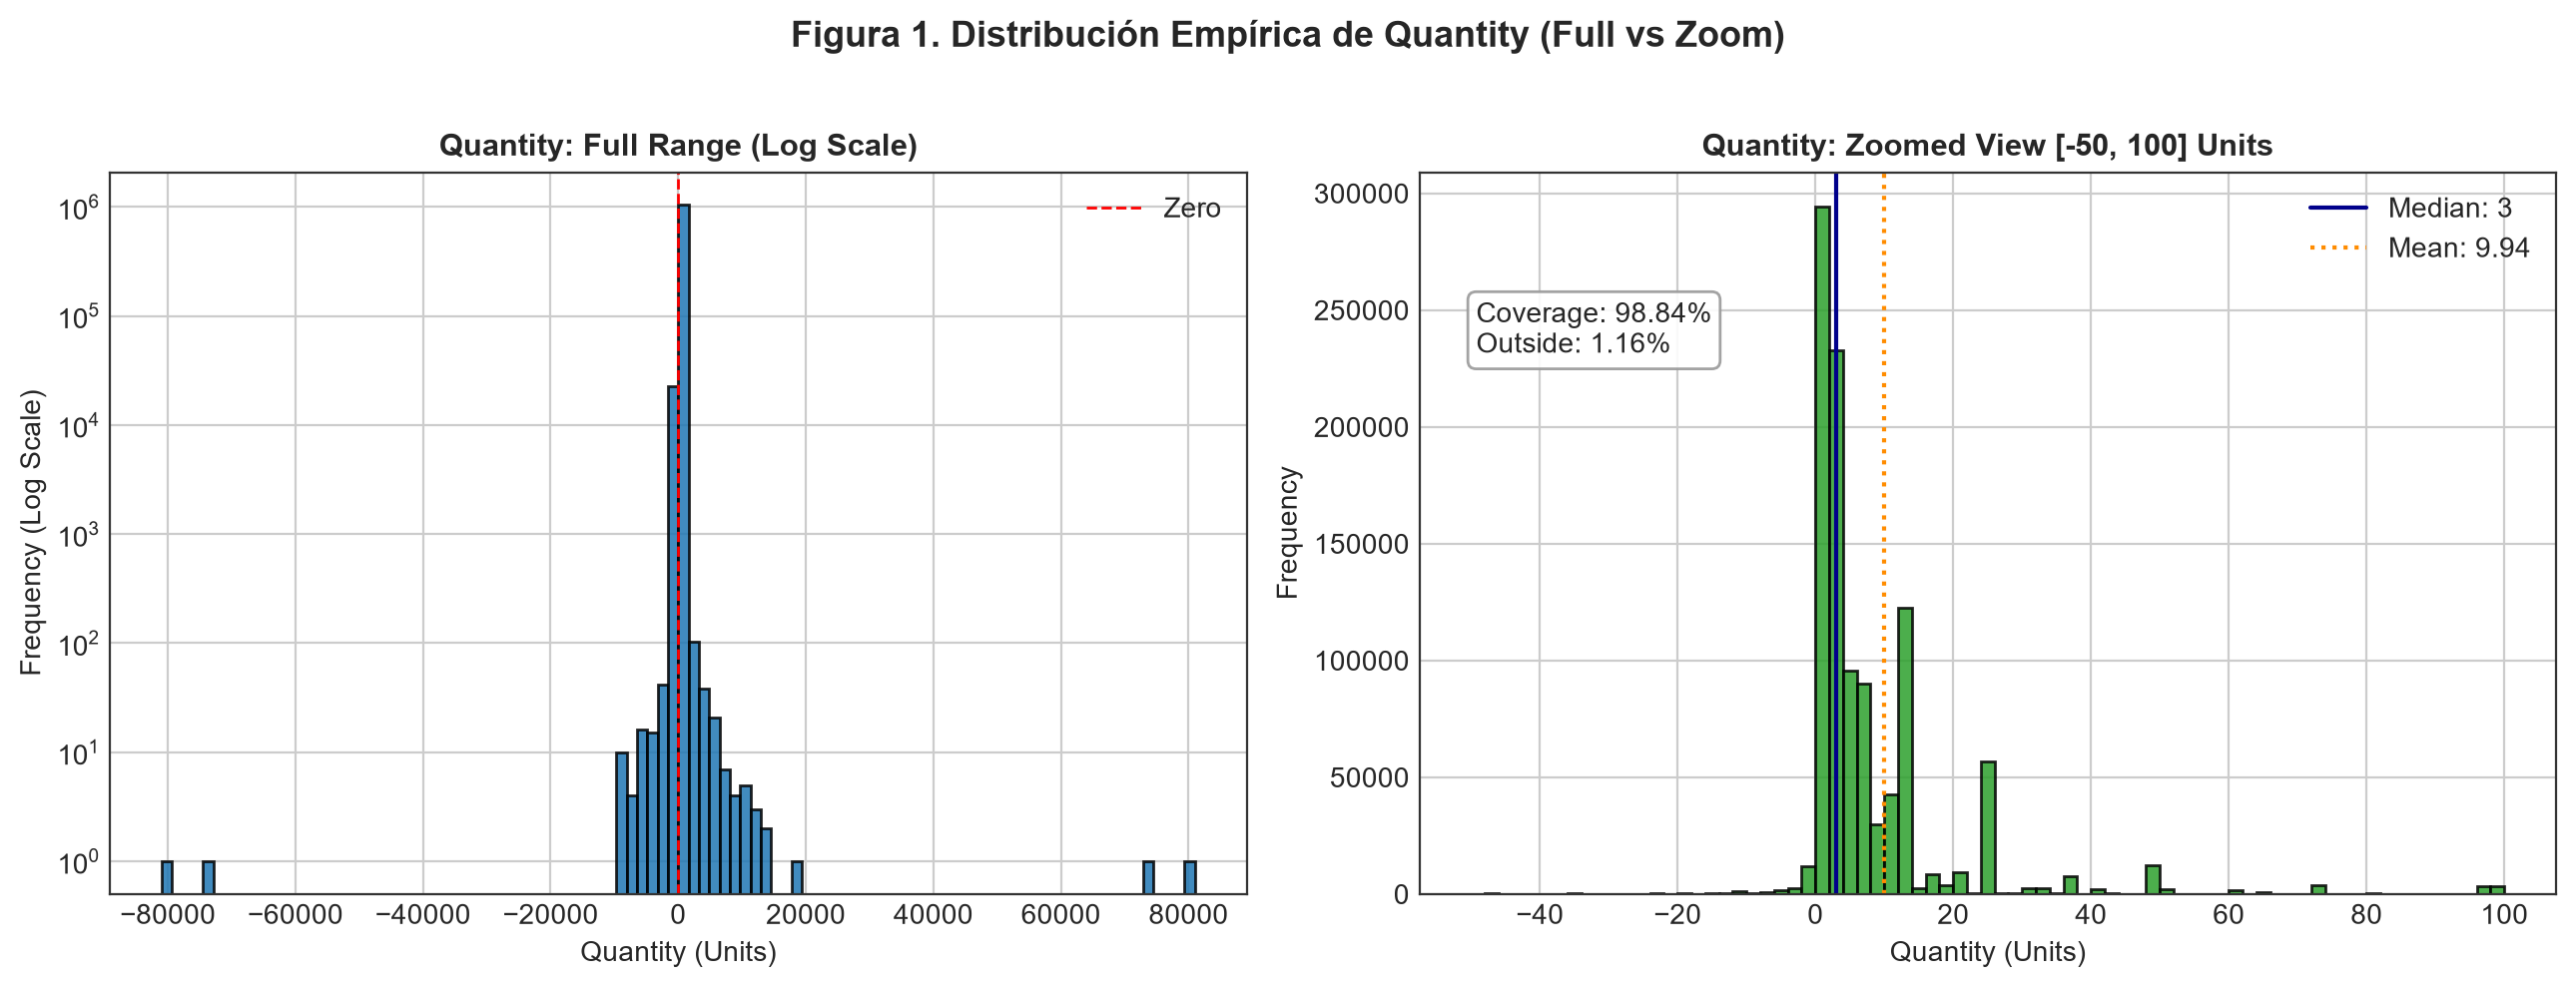

In [9]:
# Figuras 1 y 2: Histogramas de Quantity y Price (Rango Completo + Zoom)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), dpi=200)

# Quantity: Full Range
ax1.hist(df['Quantity'], bins=100, color='#1f77b4', edgecolor='black', alpha=0.85)
ax1.set_yscale('log')
ax1.set_title("Quantity: Full Range (Log Scale)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Quantity (Units)")
ax1.set_ylabel("Frequency (Log Scale)")
ax1.axvline(0, color='red', linestyle='--', linewidth=1, label='Zero')
ax1.legend()

# Quantity: Zoomed View [-50, 100]
q_mask = (df['Quantity'] >= -50) & (df['Quantity'] <= 100)
q_zoom = df.loc[q_mask, 'Quantity']
q_outside = (1.0 - len(q_zoom) / len(df)) * 100

ax2.hist(q_zoom, bins=75, color='#2ca02c', edgecolor='black', alpha=0.85)
ax2.set_title("Quantity: Zoomed View [-50, 100] Units", fontsize=11, fontweight='bold')
ax2.set_xlabel("Quantity (Units)")
ax2.set_ylabel("Frequency")
ax2.axvline(df['Quantity'].median(), color='darkblue', linestyle='-', linewidth=1.5, label=f'Median: {df["Quantity"].median():.0f}')
ax2.axvline(df['Quantity'].mean(), color='darkorange', linestyle=':', linewidth=1.5, label=f'Mean: {df["Quantity"].mean():.2f}')
ax2.text(0.05, 0.75, f"Coverage: {100-q_outside:.2f}%\nOutside: {q_outside:.2f}%", transform=ax2.transAxes, 
         bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#999999", alpha=0.9))
ax2.legend()
plt.suptitle("Figura 1. Distribución Empírica de Quantity (Full vs Zoom)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("figures/fig1_quantity_hist.png", dpi=300, bbox_inches='tight')
plt.show()

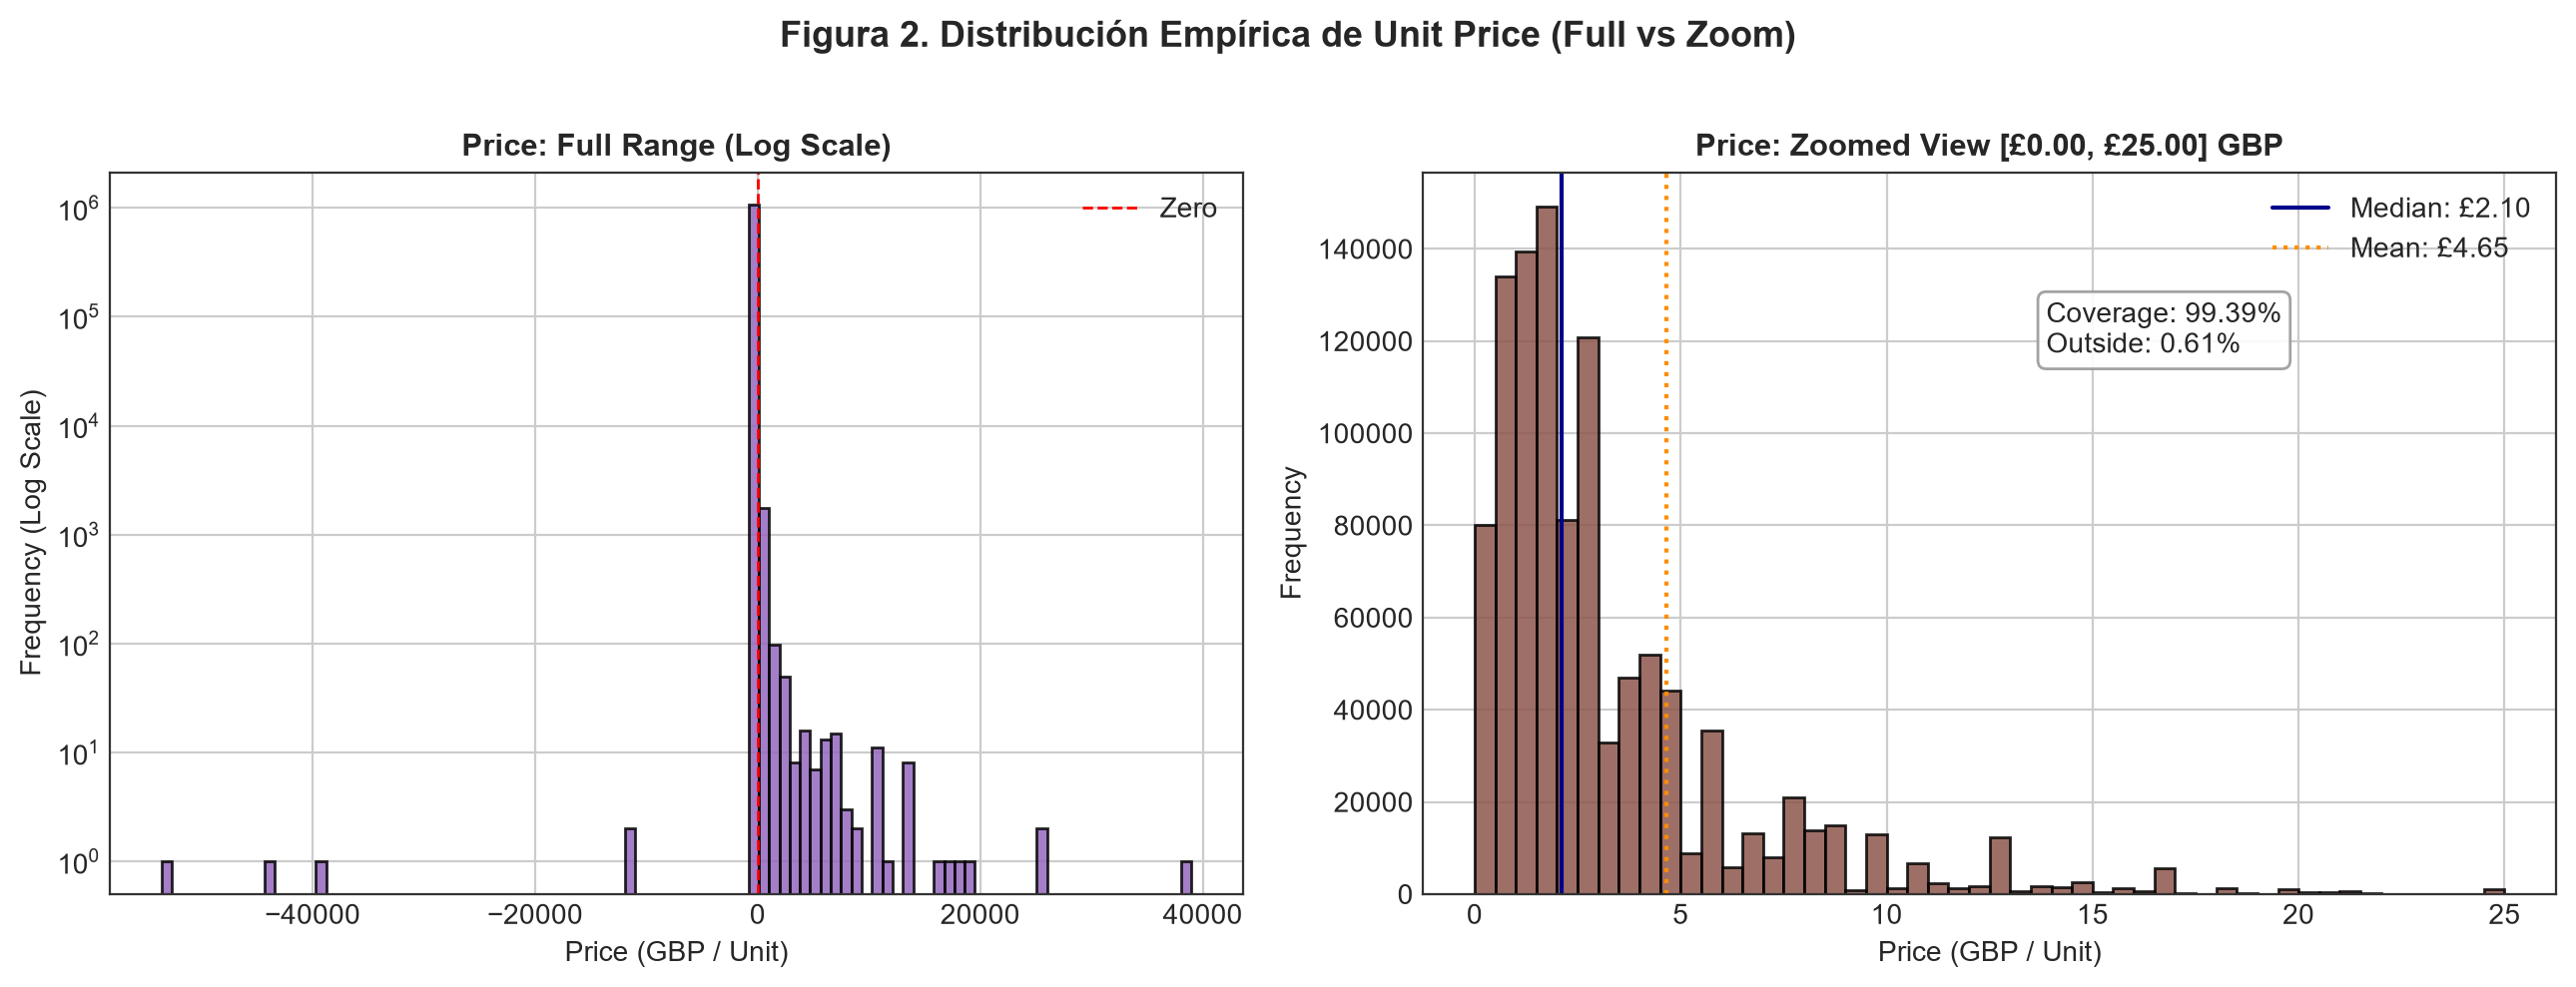

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), dpi=200)

# Price: Full Range
ax1.hist(df['Price'], bins=100, color='#9467bd', edgecolor='black', alpha=0.85)
ax1.set_yscale('log')
ax1.set_title("Price: Full Range (Log Scale)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Price (GBP / Unit)")
ax1.set_ylabel("Frequency (Log Scale)")
ax1.axvline(0, color='red', linestyle='--', linewidth=1, label='Zero')
ax1.legend()

# Price: Zoomed View [0, 25]
p_mask = (df['Price'] >= 0) & (df['Price'] <= 25)
p_zoom = df.loc[p_mask, 'Price']
p_outside = (1.0 - len(p_zoom) / len(df)) * 100

ax2.hist(p_zoom, bins=50, color='#8c564b', edgecolor='black', alpha=0.85)
ax2.set_title("Price: Zoomed View [£0.00, £25.00] GBP", fontsize=11, fontweight='bold')
ax2.set_xlabel("Price (GBP / Unit)")
ax2.set_ylabel("Frequency")
ax2.axvline(df['Price'].median(), color='darkblue', linestyle='-', linewidth=1.5, label=f'Median: £{df["Price"].median():.2f}')
ax2.axvline(df['Price'].mean(), color='darkorange', linestyle=':', linewidth=1.5, label=f'Mean: £{df["Price"].mean():.2f}')
ax2.text(0.55, 0.75, f"Coverage: {100-p_outside:.2f}%\nOutside: {p_outside:.2f}%", transform=ax2.transAxes, 
         bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#999999", alpha=0.9))
ax2.legend()
plt.suptitle("Figura 2. Distribución Empírica de Unit Price (Full vs Zoom)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("figures/fig2_price_hist.png", dpi=300, bbox_inches='tight')
plt.show()

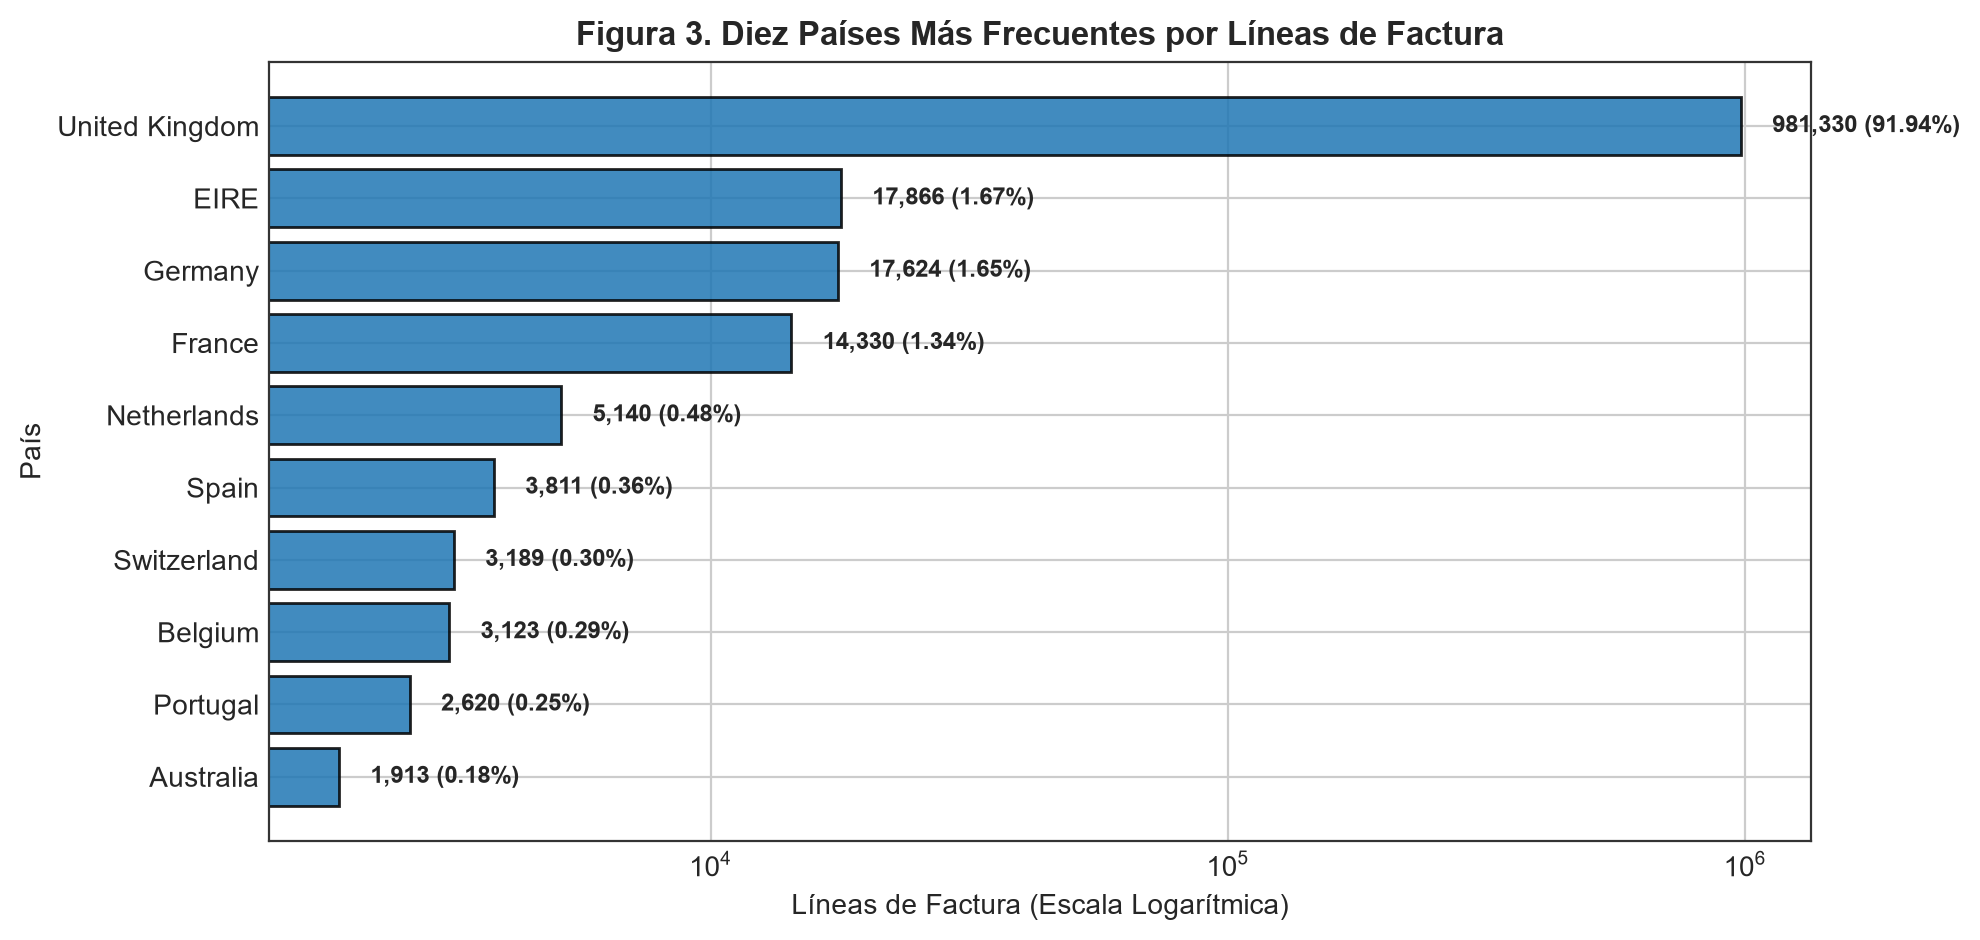

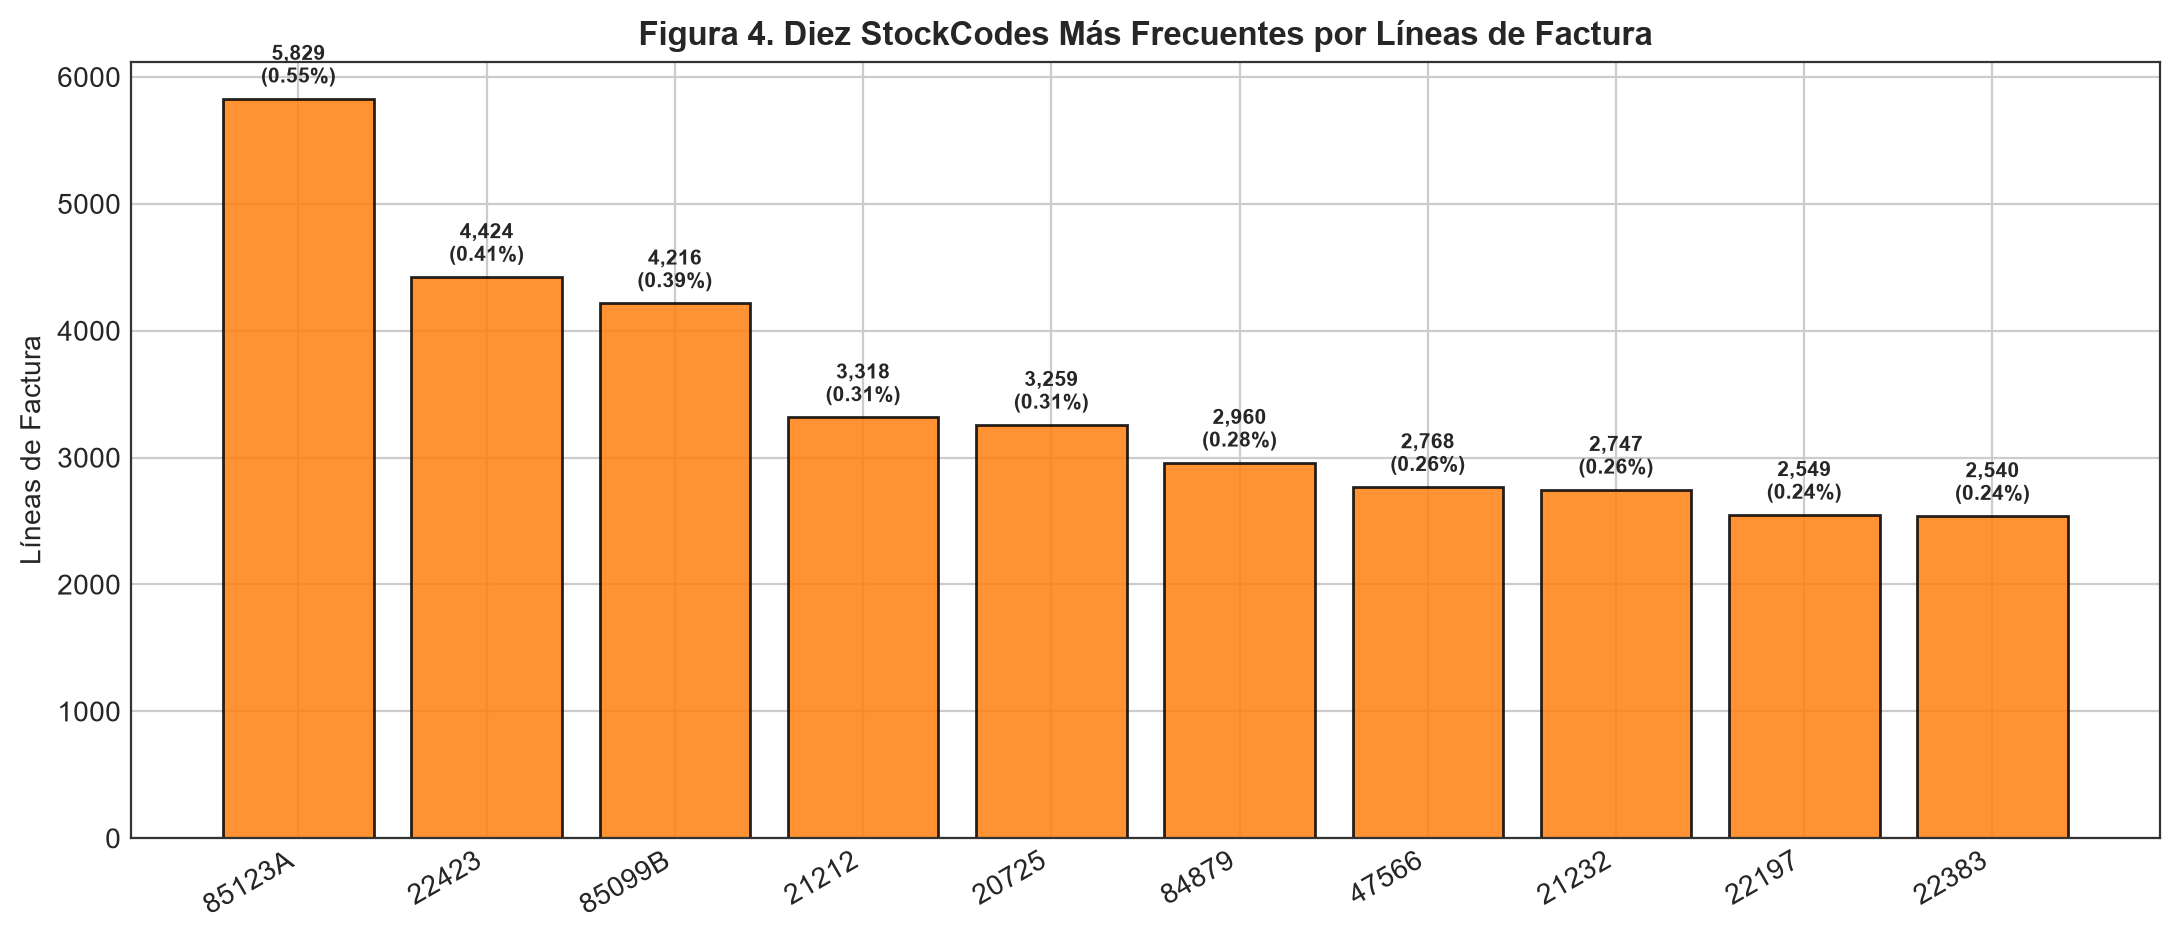

In [11]:
# Figuras 3 y 4: Frecuencias de Country y StockCode
top10_c = df['Country'].value_counts().head(10)
top10_c_pct = (top10_c / len(df)) * 100

plt.figure(figsize=(10, 4.8), dpi=200)
bars = plt.barh(top10_c.index[::-1], top10_c.values[::-1], color='#1f77b4', edgecolor='black', alpha=0.85)
plt.title("Figura 3. Diez Países Más Frecuentes por Líneas de Factura", fontsize=12, fontweight='bold')
plt.xlabel("Líneas de Factura (Escala Logarítmica)")
plt.ylabel("País")
plt.xscale('log')
for bar, count, pct in zip(bars, top10_c.values[::-1], top10_c_pct.values[::-1]):
    plt.text(count * 1.15, bar.get_y() + bar.get_height()/2, f"{count:,} ({pct:.2f}%)", va='center', fontsize=8.5, fontweight='bold')
plt.tight_layout()
plt.savefig("figures/fig3_country_bar.png", dpi=300, bbox_inches='tight')
plt.show()

# StockCode
top10_s = df['StockCode'].value_counts().head(10)
top10_s_pct = (top10_s / len(df)) * 100

plt.figure(figsize=(11, 4.8), dpi=200)
bars = plt.bar(range(10), top10_s.values, color='#ff7f0e', edgecolor='black', alpha=0.85)
plt.xticks(range(10), top10_s.index, rotation=30, ha='right')
plt.title("Figura 4. Diez StockCodes Más Frecuentes por Líneas de Factura", fontsize=12, fontweight='bold')
plt.ylabel("Líneas de Factura")
for bar, count, pct in zip(bars, top10_s.values, top10_s_pct.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80, f"{count:,}\n({pct:.2f}%)", va='bottom', ha='center', fontsize=7.5, fontweight='bold')
plt.tight_layout()
plt.savefig("figures/fig4_stockcode_bar.png", dpi=300, bbox_inches='tight')
plt.show()

In [12]:
# Tabla de 3 categorías más frecuentes para Country y StockCode
top3_country_data = df['Country'].value_counts().head(3)
top3_stock_data = df['StockCode'].value_counts().head(3)

top3_table = pd.DataFrame({
    'Variable': ['Country', 'StockCode'],
    'Categorías distintas': [f"{df['Country'].nunique():,}", f"{df['StockCode'].nunique():,}"],
    'Tres categorías más frecuentes con líneas y porcentaje': [
        "; ".join([f"{cat}: {cnt:,} ({cnt/len(df)*100:.2f}%)" for cat, cnt in top3_country_data.items()]),
        "; ".join([f"{cat}: {cnt:,} ({cnt/len(df)*100:.2f}%)" for cat, cnt in top3_stock_data.items()])
    ]
})
top3_table

,Variable,Categorías distintas,Tres categorías más frecuentes con líneas y porcentaje
0,Country,43,"United Kingdom: 981,330 (91.94%); EIRE: 17,866..."
1,StockCode,"5,305","85123A: 5,829 (0.55%); 22423: 4,424 (0.41%); 8..."


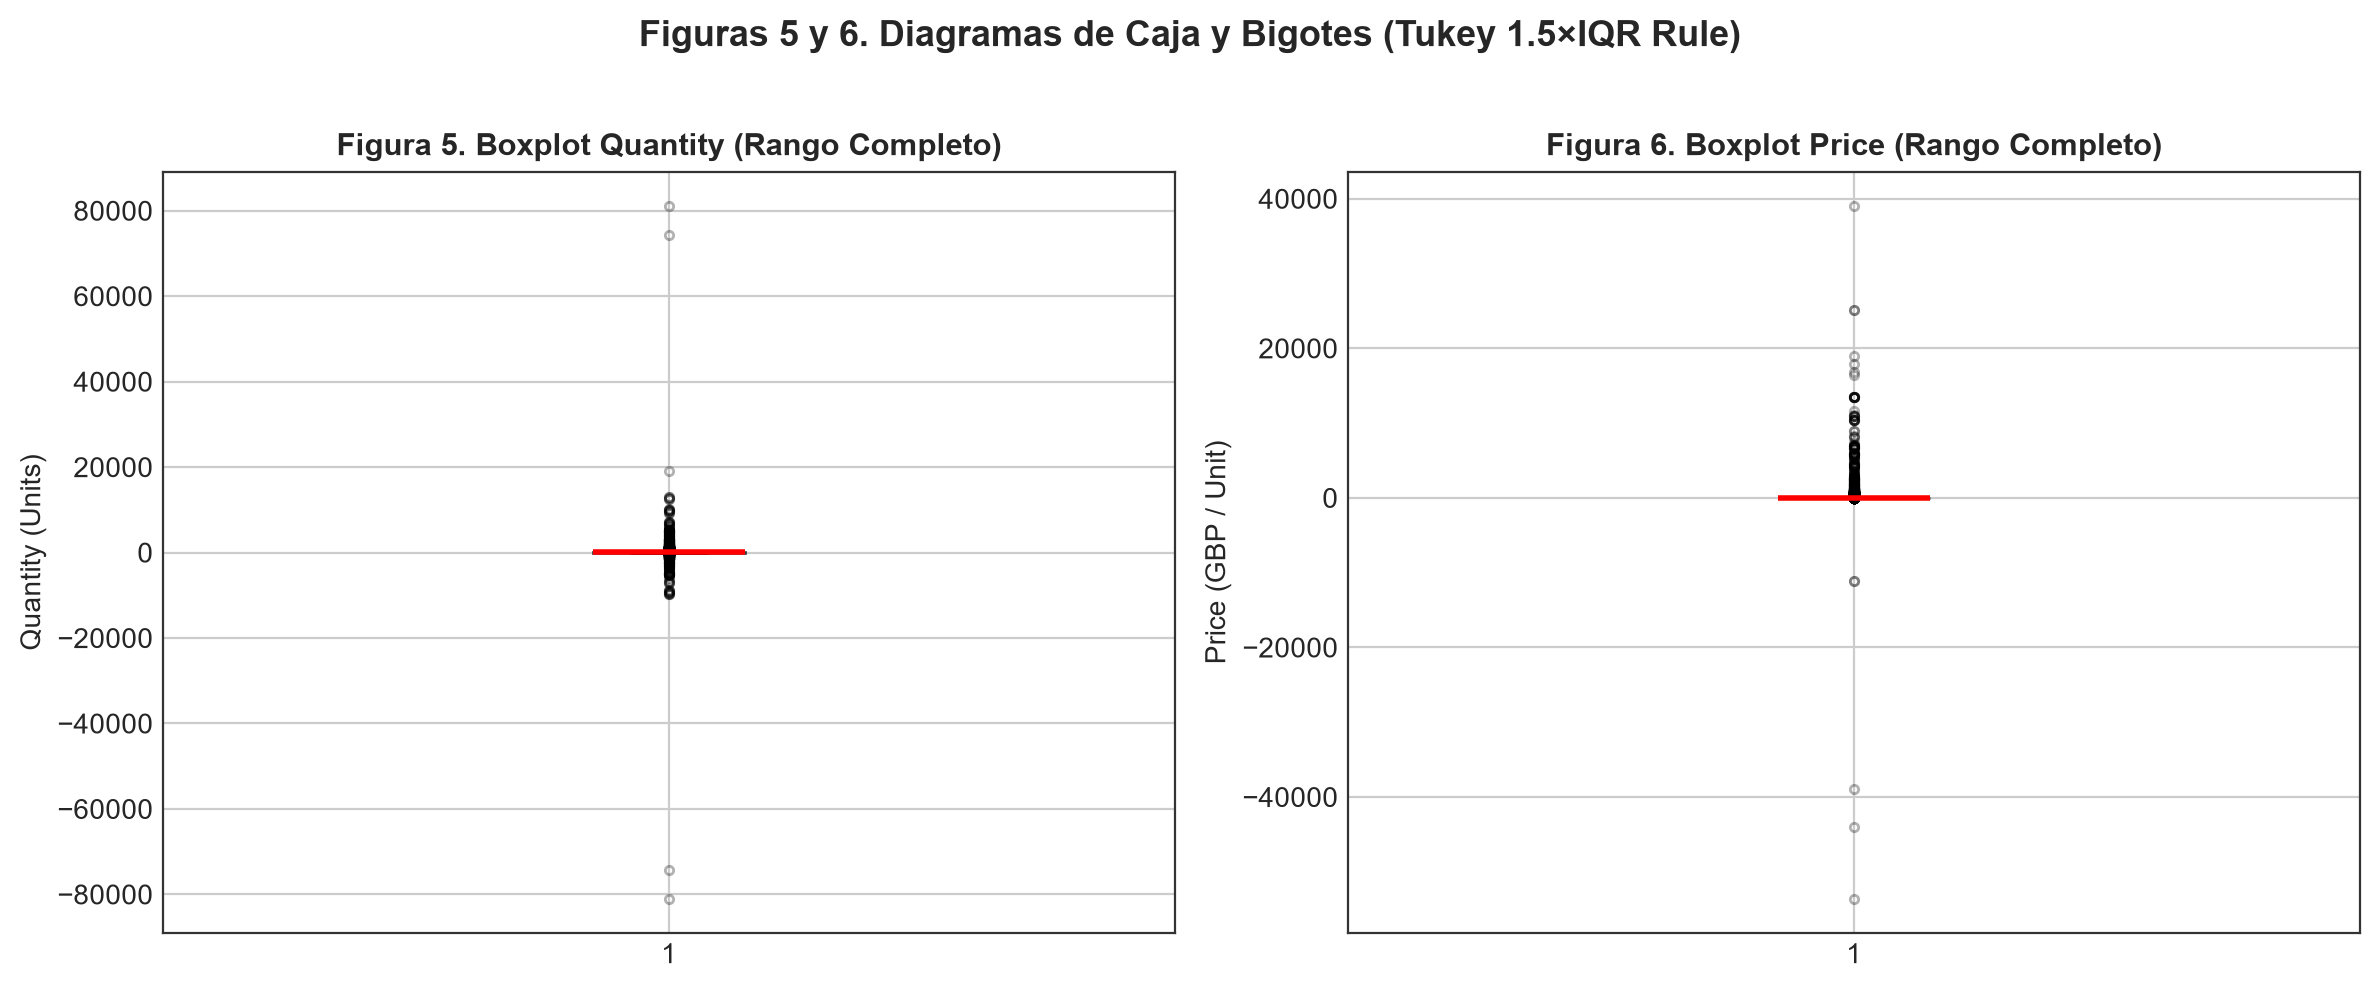

In [13]:
# Figuras 5 y 6: Boxplots de Quantity y Price
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), dpi=200)

# Quantity
ax1.boxplot(df['Quantity'], orientation='vertical', patch_artist=True,
            boxprops=dict(facecolor='#1f77b4', color='black', alpha=0.7),
            medianprops=dict(color='red', linewidth=2),
            flierprops=dict(marker='o', markersize=3, alpha=0.3))
ax1.set_title("Figura 5. Boxplot Quantity (Rango Completo)", fontsize=11, fontweight='bold')
ax1.set_ylabel("Quantity (Units)")

# Price
ax2.boxplot(df['Price'], orientation='vertical', patch_artist=True,
            boxprops=dict(facecolor='#9467bd', color='black', alpha=0.7),
            medianprops=dict(color='red', linewidth=2),
            flierprops=dict(marker='o', markersize=3, alpha=0.3))
ax2.set_title("Figura 6. Boxplot Price (Rango Completo)", fontsize=11, fontweight='bold')
ax2.set_ylabel("Price (GBP / Unit)")

plt.suptitle("Figuras 5 y 6. Diagramas de Caja y Bigotes (Tukey 1.5×IQR Rule)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("figures/fig5_6_boxplots.png", dpi=300, bbox_inches='tight')
plt.show()

---
## 4. Diagnóstico de Calidad de Datos
Evaluación exhaustiva de completitud (valores nulos con denominador homogéneo), registros duplicados y anomalías de precios no positivos y cantidades.

In [14]:
# Tabla de Nulos con denominador homogéneo
n_total = len(df)
null_diag = pd.DataFrame({
    'Columna': df.columns[:8],
    'Nulos': [df[col].isna().sum() for col in df.columns[:8]],
    'Porcentaje sobre el total': [f"{(df[col].isna().sum() / n_total * 100):.4f}%" for col in df.columns[:8]]
})
null_diag

,Columna,Nulos,Porcentaje sobre el total
0,Invoice,0,0.0000%
1,StockCode,0,0.0000%
2,Description,4382,0.4105%
3,Quantity,0,0.0000%
4,InvoiceDate,0,0.0000%
5,Price,0,0.0000%
6,Customer ID,243007,22.7669%
7,Country,0,0.0000%


In [15]:
# Tabla de situaciones anómalas
n_dups = df.duplicated().sum()
n_q_neg = (df['Quantity'] < 0).sum()
n_q_zero = (df['Quantity'] == 0).sum()
n_p_neg = (df['Price'] < 0).sum()
n_p_zero = (df['Price'] == 0).sum()

situations_df = pd.DataFrame({
    'Situación': [
        'Duplicados exactos adicionales',
        'Quantity < 0',
        'Quantity = 0',
        'Price < 0',
        'Price = 0'
    ],
    'Líneas': [f"{n_dups:,}", f"{n_q_neg:,}", f"{n_q_zero:,}", f"{n_p_neg:,}", f"{n_p_zero:,}"],
    'Porcentaje sobre el total': [
        f"{(n_dups / n_total * 100):.4f}%",
        f"{(n_q_neg / n_total * 100):.4f}%",
        f"{(n_q_zero / n_total * 100):.4f}%",
        f"{(n_p_neg / n_total * 100):.4f}%",
        f"{(n_p_zero / n_total * 100):.4f}%"
    ]
})
situations_df

,Situación,Líneas,Porcentaje sobre el total
0,Duplicados exactos adicionales,"34,335",3.2168%
1,Quantity < 0,"22,950",2.1501%
2,Quantity = 0,0,0.0000%
3,Price < 0,5,0.0005%
4,Price = 0,"6,202",0.5811%


In [16]:
# Pregunta 11: Inspección de ejemplos de duplicados y precios no positivos
print("--- EJEMPLOS DE DUPLICADOS EXACTOS ADICIONALES ---")
dup_examples = df[df.duplicated(keep=False)].sort_values(by=['Invoice', 'StockCode']).head(4)
print(dup_examples[['Invoice', 'StockCode', 'Quantity', 'Price', 'Description', 'Customer ID', 'InvoiceDate']])

print("\n--- CASOS DE PRECIO NEGATIVO (Price < 0) ---")
p_neg_cases = df[df['Price'] < 0]
print(p_neg_cases[['Invoice', 'StockCode', 'Quantity', 'Price', 'Description', 'Customer ID']])

print("\n--- EJEMPLOS DE PRECIO CERO (Price == 0) ---")
p_zero_sample = df[df['Price'] == 0].head(4)
print(p_zero_sample[['Invoice', 'StockCode', 'Quantity', 'Price', 'Description', 'Customer ID']])

--- EJEMPLOS DE DUPLICADOS EXACTOS ADICIONALES ---


    Invoice StockCode  Quantity  Price                       Description  \
379  489517     21491         1 1.9500   SET OF THREE VINTAGE GIFT WRAPS   
391  489517     21491         1 1.9500   SET OF THREE VINTAGE GIFT WRAPS   
365  489517     21821         1 3.7500  GLITTER STAR GARLAND WITH BELLS    
386  489517     21821         1 3.7500  GLITTER STAR GARLAND WITH BELLS    

     Customer ID          InvoiceDate  
379   16329.0000  2009-12-01 11:34:00  
391   16329.0000  2009-12-01 11:34:00  
365   16329.0000  2009-12-01 11:34:00  
386   16329.0000  2009-12-01 11:34:00  

--- CASOS DE PRECIO NEGATIVO (Price < 0) ---
        Invoice StockCode  Quantity       Price      Description  Customer ID
179403  A506401         B         1 -53594.3600  Adjust bad debt          NaN
276274  A516228         B         1 -44031.7900  Adjust bad debt          NaN
403472  A528059         B         1 -38925.8700  Adjust bad debt          NaN
825444  A563186         B         1 -11062.0600  Adjust bad d

---
## 5. Investigación de Cancelaciones y Cantidades Negativas
Desagregación entre anulaciones comerciales de clientes (prefijo 'C') y mermas operativas internas de almacén.

In [17]:
# 5.A: Facturas con prefijo 'C'
is_c = df['Invoice'].astype(str).str.startswith('C')
c_lines = is_c.sum()
c_inv_distinct = df[is_c]['Invoice'].nunique()
c_q_neg = (is_c & (df['Quantity'] < 0)).sum()
c_q_zero = (is_c & (df['Quantity'] == 0)).sum()
c_q_pos = (is_c & (df['Quantity'] > 0)).sum()

c_table = pd.DataFrame({
    'Indicador': [
        'Líneas con prefijo C',
        'Facturas C distintas',
        'Líneas C con Quantity < 0',
        'Líneas C con Quantity = 0',
        'Líneas C con Quantity > 0'
    ],
    'Resultado': [
        f"{c_lines:,}",
        f"{c_inv_distinct:,}",
        f"{c_q_neg:,}",
        f"{c_q_zero:,}",
        f"{c_q_pos:,}"
    ]
})
c_table

,Indicador,Resultado
0,Líneas con prefijo C,"19,494"
1,Facturas C distintas,"8,292"
2,Líneas C con Quantity < 0,"19,493"
3,Líneas C con Quantity = 0,0
4,Líneas C con Quantity > 0,1


In [18]:
# Inspección de la anomalía: Línea C con Quantity > 0
c_pos_line = df[is_c & (df['Quantity'] > 0)]
print("Línea anómala: Prefijo C con Quantity > 0:")
print(c_pos_line[['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'Customer ID', 'Country']])

Línea anómala: Prefijo C con Quantity > 0:
       Invoice StockCode Description  Quantity    Price  Customer ID  \
76799  C496350         M      Manual         1 373.5700          NaN   

              Country  
76799  United Kingdom  


In [19]:
# 5.B: Cantidades negativas SIN prefijo C
no_c_neg = (~is_c & (df['Quantity'] < 0))
no_c_lines = no_c_neg.sum()
no_c_inv_distinct = df[no_c_neg]['Invoice'].nunique()

print(f"Líneas negativas sin prefijo C: {no_c_lines:,}")
print(f"Facturas distintas asociadas: {no_c_inv_distinct:,}")
print(f"Customer IDs no nulos en estas líneas: {df[no_c_neg]['Customer ID'].notna().sum()}")
print(f"Líneas con Price == 0.0: {(df[no_c_neg]['Price'] == 0).sum():,}")

print("\nInspección de 5 casos representativos:")
print(df[no_c_neg][['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'Customer ID', 'InvoiceDate']].head(5))

Líneas negativas sin prefijo C: 3,457
Facturas distintas asociadas: 3,393
Customer IDs no nulos en estas líneas: 0
Líneas con Price == 0.0: 3,457

Inspección de 5 casos representativos:
     Invoice StockCode   Description  Quantity  Price  Customer ID  \
263   489464     21733  85123a mixed       -96 0.0000          NaN   
283   489463     71477         short      -240 0.0000          NaN   
284   489467    85123A   21733 mixed      -192 0.0000          NaN   
470   489521     21646           NaN       -50 0.0000          NaN   
3114  489655     20683           NaN       -44 0.0000          NaN   

              InvoiceDate  
263   2009-12-01 10:52:00  
283   2009-12-01 10:52:00  
284   2009-12-01 10:53:00  
470   2009-12-01 11:44:00  
3114  2009-12-01 17:26:00  


In [20]:
# 5.C: Matriz de Contingencia 2x3 (Con C vs Sin C x Signo de Quantity)
# Clasificación de Quantity
df['Quantity_Sign'] = pd.cut(df['Quantity'], bins=[-np.inf, -0.0001, 0.0001, np.inf], labels=['Quantity < 0', 'Quantity = 0', 'Quantity > 0'])
df['Invoice_Prefix'] = np.where(is_c, 'Con C', 'Sin C')

contingency_table = pd.crosstab(
    df['Invoice_Prefix'],
    df['Quantity_Sign'],
    margins=True,
    margins_name="Total"
)
contingency_table

Quantity_Sign,Quantity < 0,Quantity > 0,Total
Invoice_Prefix,,,
Con C,19493,1,19494
Sin C,3457,1044420,1047877
Total,22950,1044421,1067371


---
## 6. Plan de Acción y Evaluación
Matriz estratégica de tratamiento de anomalías para la fase CRISP-DM de Data Preparation, priorizando la integridad analítica y evaluando los riesgos residuales.

In [21]:
action_plan_df = pd.DataFrame([
    {
        "Problema identificado": "Valores nulos en Customer ID",
        "Evidencia": "243,007 líneas (22.77% del archivo). Ejemplo: Invoice 489435 no registra cliente.",
        "Posible impacto empresarial": "Sesgo de modelado en CLV y segmentación. Pérdida de 22.8% del volumen transaccional.",
        "Tratamiento propuesto": "Segmentar el pipeline: excluir para modelos de cliente individual (CLV/Churn); conservar como cohorte 'Walk-in/B2B anónimo' para proyecciones de demanda agregada."
    },
    {
        "Problema identificado": "Duplicados exactos adicionales",
        "Evidencia": "34,335 líneas adicionales (3.22%). Ejemplo: Invoice 489517 duplica ítems 21491, 21821 al mismo timestamp.",
        "Posible impacto empresarial": "Sobrestimación artificial de ingresos (£), unidades vendidas y distorsión de demanda.",
        "Tratamiento propuesto": "Deduplicar mediante df.drop_duplicates(keep='first'). Solicitar al equipo de TI auditoría de reintentos HTTP en la pasarela e-commerce."
    },
    {
        "Problema identificado": "Cantidades negativas sin prefijo C",
        "Evidencia": "3,457 líneas (0.32%), 100% con Price=0 y Customer ID nulo. Descripciones: 'damages', 'check', 'thrown away'.",
        "Posible impacto empresarial": "Confusión entre pérdidas de inventario (merma física) y transacciones comerciales de devolución.",
        "Tratamiento propuesto": "Segregar estas líneas del flujo de ventas de clientes y remitirlas a un módulo de auditoría de pérdidas operativas / merma de almacén."
    },
    {
        "Problema identificado": "Precios no positivos (Price <= 0)",
        "Evidencia": "5 líneas con Price < 0 ('Adjust bad debt', StockCode 'B', e.g. A506401 por -£53,594.36); 6,202 con Price = 0.",
        "Posible impacto empresarial": "Distorsión catastrófica de métricas monetarias (mermas contables de deuda incobrable restan millones ficticios).",
        "Tratamiento propuesto": "Excluir permanentemente las partidas contables con prefijo 'A' de las ventas minoristas. Aislar muestras promocionales (Price=0)."
    },
    {
        "Problema identificado": "Cancelaciones comerciales (Prefijo C)",
        "Evidencia": "19,494 líneas (1.83%), de las cuales 19,493 tienen Quantity < 0 y 1 tiene Quantity > 0 (C496350, Manual).",
        "Posible impacto empresarial": "Cálculo erróneo de ingresos brutos si no se concilian con la compra original.",
        "Tratamiento propuesto": "Conciliar cada anulación 'C' con su factura original para calcular ventas netas reales y construir la tasa de retorno por cliente."
    }
])
action_plan_df

,Problema identificado,Evidencia,Posible impacto empresarial,Tratamiento propuesto
0,Valores nulos en Customer ID,"243,007 líneas (22.77% del archivo). Ejemplo: ...",Sesgo de modelado en CLV y segmentación. Pérdi...,Segmentar el pipeline: excluir para modelos de...
1,Duplicados exactos adicionales,"34,335 líneas adicionales (3.22%). Ejemplo: In...","Sobrestimación artificial de ingresos (£), uni...",Deduplicar mediante df.drop_duplicates(keep='f...
2,Cantidades negativas sin prefijo C,"3,457 líneas (0.32%), 100% con Price=0 y Custo...",Confusión entre pérdidas de inventario (merma ...,Segregar estas líneas del flujo de ventas de c...
3,Precios no positivos (Price <= 0),"5 líneas con Price < 0 ('Adjust bad debt', Sto...",Distorsión catastrófica de métricas monetarias...,Excluir permanentemente las partidas contables...
4,Cancelaciones comerciales (Prefijo C),"19,494 líneas (1.83%), de las cuales 19,493 ti...",Cálculo erróneo de ingresos brutos si no se co...,Conciliar cada anulación 'C' con su factura or...
